**Name:** Fredrick Kimutai 
**Student number:** 2024658 
**GitHub repository:** https://github.com/2024658/data_exploration_ca_1

# Electricity Generation Across Countries
**Domain:** Energy 
**Data:** Our World in Data energy dataset 
**Tools:** pandas, matplotlib, seaborn, scikit-learn

**Research question:** How do countries' electricity mixes differ, and which measures (energy sources, demand, income, carbon intensity) explain the main differences?

Put `owid_energy.csv` in the same folder as this notebook, then choose *Run All*.

## 1. Data preparation

### 1.1 Load the data and examine


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

raw = pd.read_csv("owid_energy.csv")
print("Rows and columns:", raw.shape)
print(raw.dtypes.value_counts())
raw[["country", "year", "iso_code", "population", "gdp"]].head()

Rows and columns: (19494, 130)
float64    127
str          2
int64        1
Name: count, dtype: int64


,country,year,iso_code,population,gdp
0,ASEAN (Ember),2000,NaN,NaN,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN


The file has one row per country per year and 130 columns, almost all numeric.

### 1.2 Keep real countries and recent years
Rows like "World" or "Asia" are totals, not countries, so they would double count. They have a blank `iso_code` or one that starts with `OWID`. I also keep only 2000 to 2024, because electricity data is patchy before that.

In [9]:
iso = raw["iso_code"].fillna("")                     
df = raw[(iso != "") & (~iso.str.startswith("OWID"))]
df = df[(df["year"] >= 2000) & (df["year"] <= 2024)]
print("Countries:", df["country"].nunique(), "| rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

Countries: 220 | rows: 5468
Duplicate rows: 0


### 1.3 Choosing Columns and Handling Missing Values
From the 130 raw attributes, I retain **14 domain-relevant columns** covering demographics and economic scale **(country, year, population, gdp)**, electricity generation shares (coal, gas, oil, nuclear, hydro, solar, wind, renewables), per-capita demand, and carbon intensity. Missing values are handled via **listwise deletion (dropna())** rather than imputation A blank electricity share does not  mean 0%, and filling with an average would distort very different national energy profiles. Because gdp has the highest missingness (**30.7%**, including 2023–2024), dropping incomplete rows reduces the dataset from **5,468 to 3,547 rows** across **159 countries (2000–2022)**a trade-off that preserves data accuracy while still exceeding the 3,000-row requirement.

In [13]:
columns = ["country", "year", "population", "gdp",
           "coal_electricity_share_pct", "gas_electricity_share_pct",
           "oil_electricity_share_pct", "nuclear_electricity_share_pct",
           "hydro_electricity_share_pct", "solar_electricity_share_pct",
           "wind_electricity_share_pct", "renewables_electricity_share_pct",
           "electricity_demand_per_capita_kwh",
           "electricity_carbon_intensity_gco2eq_per_kwh"]
df = df[columns].copy()

print("Missing values per column (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))

df = df.dropna()          # remove any row with a missing value
print("Rows after dropping missing values:", len(df))

Missing values per column (%):
country                                        0.0
year                                           0.0
population                                     0.0
gdp                                            0.0
coal_electricity_share_pct                     0.0
gas_electricity_share_pct                      0.0
oil_electricity_share_pct                      0.0
nuclear_electricity_share_pct                  0.0
hydro_electricity_share_pct                    0.0
solar_electricity_share_pct                    0.0
wind_electricity_share_pct                     0.0
renewables_electricity_share_pct               0.0
electricity_demand_per_capita_kwh              0.0
electricity_carbon_intensity_gco2eq_per_kwh    0.0
dtype: float64
Rows after dropping missing values: 3547


### 1.4 Created New Features

I createdd six additional features to support comparisons, visualisation and encoding:

- **`gdp_per_capita`**: Divides GDP by population to compare economic output per person across countries.
- **`wind_solar_share_pct`**: Combines wind and solar electricity shares into one measure.
- **`log_demand` and `log_gdp_pc`**: Reduce right-skewness in electricity demand per person and GDP per capita before correlation analysis and PCA. Demand uses `log(demand + 1)` to handle zeros; GDP per capita must be positive.
- **`period`**: Groups years into three ordered periods (`2000–2009`, `2010–2019`, `2020–2024`) for ordinal encoding. After cleaning, the available data ends in 2022.
- **`dominant_source`**: Identifies the largest share among the selected source categories for each country-year, treating wind and solar as a combined category. This supports visual grouping and one-hot encoding(does not include other renewables and bioenergy)

In [15]:
df["gdp_per_capita"] = df["gdp"] / df["population"]
df["wind_solar_share_pct"] = df["wind_electricity_share_pct"] + df["solar_electricity_share_pct"]

# Log transforms: demand and income are very skewed
df["log_demand"] = np.log(df["electricity_demand_per_capita_kwh"] + 1)
df["log_gdp_pc"] = np.log(df["gdp_per_capita"])

# Time period (grouping of years)
df["period"] = pd.cut(df["year"], bins=[1999, 2009, 2019, 2024],
                      labels=["2000-2009", "2010-2019", "2020-2024"])

# Dominant source = the source with the biggest share (a category)
sources = {"coal_electricity_share_pct": "Coal", "gas_electricity_share_pct": "Gas",
           "oil_electricity_share_pct": "Oil", "nuclear_electricity_share_pct": "Nuclear",
           "hydro_electricity_share_pct": "Hydro", "wind_solar_share_pct": "Wind & solar"}
df["dominant_source"] = df[list(sources)].idxmax(axis=1).map(sources)
print(df["dominant_source"].value_counts())

dominant_source
Hydro           1133
Gas              857
Oil              786
Coal             566
Nuclear          171
Wind & solar      34
Name: count, dtype: int64


### 1.5 Outliers
I use the IQR rule (values far outside the middle 50 %) on electricity demand per person.

Outliers: 225 of 3547
country
Bahrain    23
Canada     23
Finland    23
Iceland    23
Kuwait     23
Norway     23
Qatar      23
Sweden     23
Name: count, dtype: int64


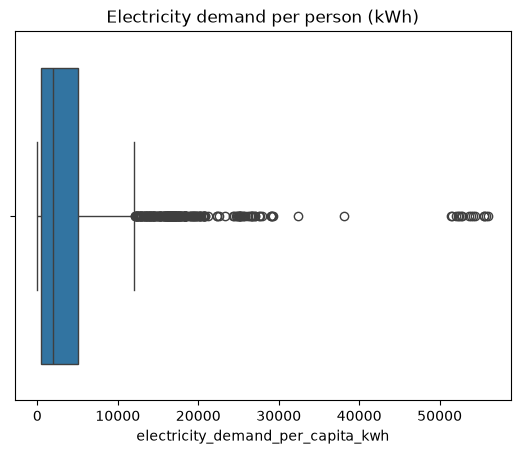

In [19]:
col = df["electricity_demand_per_capita_kwh"]
q1 = col.quantile(0.25)
q3 = col.quantile(0.75)
iqr = q3 - q1
outliers = df[(col < q1 - 1.5 * iqr) | (col > q3 + 1.5 * iqr)]
print("Outliers:", len(outliers), "of", len(df))
print(outliers["country"].value_counts().head(8))

sns.boxplot(x=col)
plt.title("Electricity demand per person (kWh)")
plt.show()

**Decision: keep them.** The outliers are real countries (for example Iceland, Norway, Canada and Gulf states) that use a lot of electricity, not data errors. Removing them would remove the extremes I want to explain. Instead, I use the **log** of demand later to reduce their effect.

### 1.6 Check the final size

In [20]:
print("Final data:", df.shape[0], "rows and", df.shape[1], "columns")
print("Countries:", df["country"].nunique(), "| years:", df["year"].min(), "to", df["year"].max())
print("At least 3000 rows and 7 columns?", df.shape[0] >= 3000 and df.shape[1] >= 7)

Final data: 3547 rows and 20 columns
Countries: 159 | years: 2000 to 2022
At least 3000 rows and 7 columns? True


**Challenges:** totals mixed with countries; many missing values (dropping them reduces the data and mostly removes small or poorly reported countries, so results lean towards better reported countries), very skewed values and shares that add up to about 100 %, which makes them partly dependent on each other.